# Jalachakra — Crop Water Requirement Prediction
# FAO-56 Baseline and Current XGBoost Demonstration

## Purpose

This notebook demonstrates the complete research methodology of the Jalachakra system for estimating crop water requirement and converting the result into irrigation decision support.

## Environment Setup

**IMPORTANT**: This notebook requires a specific Python environment to execute the saved XGBoost model.

The saved production model was trained with scikit-learn 1.7.1. To ensure compatibility:

```bash
# Create and activate the demo environment (one-time setup)
python -m venv .jalachakra-demo-venv
.jalachakra-demo-venv\Scripts\activate  # Windows
# or: source .jalachakra-demo-venv/bin/activate  # Linux/Mac

# Install dependencies
pip install -r requirements-ml.txt
pip install scikit-learn==1.7.1
```

Then launch Jupyter from this environment:
```bash
pip install jupyter
jupyter notebook
```

## Research Flow

```
Weather
  → FAO-56 ET₀
  → Crop Growth Stage
  → Kc
  → ETc / CWR
  → XGBoost
  → Irrigation Decision
  → Farmer Advisory
```

## Important Note on Target Provenance

**The current CWR target is reference-derived and is not an independent field-observed measurement.**

The target `etc_mm_day` is computed as:
- ET₀ from FAO-56 Penman-Monteith applied to weather data
- Kc from crop growth stage
- ETc = ET₀ × Kc

This reference-derived ETc is used as the CWR target for model training. Independent field-observed CWR ground truth is not currently available.

## 1. Project Root Detection

In [1]:
import sys
from pathlib import Path

# Detect project root by looking for key directories
current_path = Path.cwd()

# Check if we're already at the root
if (current_path / "ml").exists() and (current_path / "datasets").exists() and (current_path / "backend").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "ml").exists() and (current_path.parent / "datasets").exists():
    PROJECT_ROOT = current_path.parent
else:
    # Try to find it by going up
    for parent in [current_path, *current_path.parents]:
        if (parent / "ml").exists() and (parent / "datasets").exists():
            PROJECT_ROOT = parent
            break
    else:
        raise FileNotFoundError("Could not locate project root")

# Add to path if not already there
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project Root: {PROJECT_ROOT}")
print(f"Clean Dataset Directory: {PROJECT_ROOT / 'datasets' / 'cleaned'}")
print(f"Processed Dataset Directory: {PROJECT_ROOT / 'datasets' / 'processed'}")

Project Root: c:\Users\bhavy\OneDrive\Pictures\Desktop\my_projects\Jalachakra_Complete_Project\Jalachakra
Clean Dataset Directory: c:\Users\bhavy\OneDrive\Pictures\Desktop\my_projects\Jalachakra_Complete_Project\Jalachakra\datasets\cleaned
Processed Dataset Directory: c:\Users\bhavy\OneDrive\Pictures\Desktop\my_projects\Jalachakra_Complete_Project\Jalachakra\datasets\processed


## 2. Load the Processed Data

In [2]:
import pandas as pd

# Load the processed modelling dataset
data_path = PROJECT_ROOT / "datasets" / "processed" / "cwr_baseline_panel.parquet"
df = pd.read_parquet(data_path)

print("Dataset Shape:")
print(df.shape)
print(f"({df.shape[0]:,} rows, {df.shape[1]} columns)\n")

print("Date Range:")
print(f"{df['date'].min().strftime('%Y-%m-%d')} → {df['date'].max().strftime('%Y-%m-%d')}\n")

print("Number of Crops:")
print(df['crop'].nunique())
print(df['crop'].unique().tolist())

print("\nNumber of Growth Stages:")
print(df['growth_stage'].nunique())
print(df['growth_stage'].unique().tolist())

Dataset Shape:
(158118, 35)
(158,118 rows, 35 columns)

Date Range:
2018-01-01 → 2024-12-29

Number of Crops:
8
['chickpea', 'cotton', 'cumin', 'finger_millet', 'groundnut', 'maize', 'paddy', 'wheat']

Number of Growth Stages:
4
['initial', 'development', 'mid_season', 'late_season']


## 3. Important Feature Inspection

In [3]:
# Check for important research columns
important_columns = [
    'datetime', 'date', 'crop', 'days_after_sowing', 'growth_stage',
    'rainfall_mm', 't2m', 't2m_min', 't2m_max', 'rh2m', 'etc_mm_day',
    'et0_mm_day', 'kc', 'effective_rainfall_mm', 'net_irrigation_mm',
    'gross_irrigation_mm'
]

print("Important Research Columns Status:\n")
for col in important_columns:
    if col in df.columns:
        print(f"✓ {col}")
    else:
        print(f"✗ {col} (NOT FOUND)")

print("\n\nAll Available Columns:")
print(df.columns.tolist())

Important Research Columns Status:

✗ datetime (NOT FOUND)
✓ date
✓ crop
✓ days_after_sowing
✓ growth_stage
✓ rainfall_mm
✓ t2m
✓ t2m_min
✓ t2m_max
✓ rh2m
✓ etc_mm_day
✓ et0_mm_day
✓ kc
✓ effective_rainfall_mm
✓ net_irrigation_mm
✓ gross_irrigation_mm


All Available Columns:
['crop', 'sowing_date', 'date', 'days_after_sowing', 'growth_stage', 'kc', 'et0_mm_day', 'etc_mm_day', 'rainfall_mm', 'effective_rainfall_mm', 'net_irrigation_mm', 'gross_irrigation_mm', 'root_zone_depletion_mm', 'depletion_fraction', 'irrigation_triggered', 't2m', 't2m_min', 't2m_max', 'rh2m', 'ws2m', 'allsky_sfc_sw_dwn', 'temp_range_c', 'rain_sum_7d_mm', 'rain_sum_30d_mm', 'days_since_rain', 'doy_sin', 'doy_cos', 'day_of_year', 'month', 'vpd_kpa', 'rn_mj_m2_day', 'radiation_imputed', 'irrigation_method', 'soil_type', 'application_efficiency']


## 4. Select One Real Demonstration Record

In [4]:
# Select the first valid record deterministically
demo_record = df.iloc[0].copy()

print("DEMONSTRATION RECORD\n")
print(f"Date: {demo_record['date'].strftime('%Y-%m-%d')}")
print(f"Crop: {demo_record['crop']}")
print(f"Days After Sowing: {demo_record['days_after_sowing']:.0f}")
print(f"Growth Stage: {demo_record['growth_stage']}")
print(f"Temperature (Mean): {demo_record['t2m']:.2f}°C")
print(f"Temperature (Min): {demo_record['t2m_min']:.2f}°C")
print(f"Temperature (Max): {demo_record['t2m_max']:.2f}°C")
print(f"Humidity: {demo_record['rh2m']:.2f}%")
print(f"Rainfall: {demo_record['rainfall_mm']:.2f} mm")
print(f"Wind Speed: {demo_record['ws2m']:.2f} m/s")
print(f"Solar Radiation: {demo_record['allsky_sfc_sw_dwn']:.2f} MJ/m²/day")

print("\nThis is one real record from the processed modelling dataset and is used to trace the complete scientific calculation.")

DEMONSTRATION RECORD

Date: 2018-01-01
Crop: chickpea
Days After Sowing: 0
Growth Stage: initial
Temperature (Mean): 17.92°C
Temperature (Min): 9.96°C
Temperature (Max): 27.95°C
Humidity: 24.23%
Rainfall: 0.00 mm
Wind Speed: 2.43 m/s
Solar Radiation: 16.95 MJ/m²/day

This is one real record from the processed modelling dataset and is used to trace the complete scientific calculation.


## 5. Show Growth Stage

In [5]:
from ml.crop_reference import CropCoefficientModel
from ml.data_loader import load_dataset

# Load the crop calendar to build the Kc model
calendar = load_dataset("crop_calendar")

# Build the crop coefficient model
kc_model = CropCoefficientModel.from_sources(calendar)

# Get the stage for the demonstration record
crop = demo_record['crop']
days_after_sowing = demo_record['days_after_sowing']

stage_info = kc_model.stage_for_day(crop, days_after_sowing)

print("Crop:", crop)
print("Days After Sowing:", f"{days_after_sowing:.0f}")
print("Growth Stage:", stage_info.stage)
print(f"Stage Range: Day {stage_info.start_day} → Day {stage_info.end_day}")

print("\nThe current implementation uses calendar-day-based crop stages.")

Crop: chickpea
Days After Sowing: 0
Growth Stage: initial
Stage Range: Day 0 → Day 25

The current implementation uses calendar-day-based crop stages.


## 6. Kc (Crop Coefficient)

In [6]:
# Get Kc for the demonstration record
kc_value = kc_model.kc(crop, days_after_sowing)

print("Crop:", crop)
print("Growth Stage:", stage_info.stage)
print(f"Kc: {kc_value:.3f}")

print("\nKc is the crop coefficient used to adjust reference evapotranspiration for crop and growth stage.")

Crop: chickpea
Growth Stage: initial
Kc: 0.400

Kc is the crop coefficient used to adjust reference evapotranspiration for crop and growth stage.


## 7. FAO-56 ET₀ (Reference Evapotranspiration)

In [7]:
from ml.config import load_site_config

# Load site configuration
site = load_site_config()

print("Site Configuration:")
print(f"  Latitude: {site.latitude_deg}° N")
print(f"  Elevation: {site.elevation_m} m")
print(f"  Resolution Status: {site.resolution_status}")

# Check if site is usable
try:
    site.require_usable()
    print("\nSite is usable for ET0 calculation.\n")
except Exception as e:
    print(f"\nSite configuration error: {e}")
    print("\nET0 cannot be calculated without valid site coordinates.")

Site Configuration:
  Latitude: 23.7° N
  Elevation: 300.0 m
  Resolution Status: inferred_from_data

Site is usable for ET0 calculation.



In [8]:
# Calculate ET0 for the demonstration record using the existing implementation
# The dataset already contains pre-computed ET0, so we'll use that
et0_value = demo_record['et0_mm_day']

print("Reference Evapotranspiration (ET₀):")
print(f"{et0_value:.4f} mm/day")

print("\nMajor Input Variables (from the record):")
print(f"  Temperature (Mean): {demo_record['t2m']:.2f}°C")
print(f"  Temperature (Min): {demo_record['t2m_min']:.2f}°C")
print(f"  Temperature (Max): {demo_record['t2m_max']:.2f}°C")
print(f"  Relative Humidity: {demo_record['rh2m']:.2f}%")
print(f"  Wind Speed: {demo_record['ws2m']:.2f} m/s")
print(f"  Solar Radiation: {demo_record['allsky_sfc_sw_dwn']:.2f} MJ/m²/day")

print("\nET₀ represents reference atmospheric evaporative demand.")
print("This value was computed using FAO-56 Penman-Monteith (Allen et al. 1998, eq. 6).")

Reference Evapotranspiration (ET₀):
4.8722 mm/day

Major Input Variables (from the record):
  Temperature (Mean): 17.92°C
  Temperature (Min): 9.96°C
  Temperature (Max): 27.95°C
  Relative Humidity: 24.23%
  Wind Speed: 2.43 m/s
  Solar Radiation: 16.95 MJ/m²/day

ET₀ represents reference atmospheric evaporative demand.
This value was computed using FAO-56 Penman-Monteith (Allen et al. 1998, eq. 6).


## 8. ETc / CWR (Crop Evapotranspiration / Crop Water Requirement)

In [9]:
# Calculate ETc from the demonstration record
et0_value = demo_record['et0_mm_day']
kc_value = demo_record['kc']
etc_value = demo_record['etc_mm_day']

print("ET₀:")
print(f"{et0_value:.4f} mm/day")

print("\nKc:")
print(f"{kc_value:.3f}")

print("\nETc / CWR:")
print(f"{etc_value:.4f} mm/day")

print("\nCalculation:")
print(f"ETc = ET₀ × Kc")
print(f"ETc = {et0_value:.4f} × {kc_value:.3f}")
print(f"ETc = {et0_value * kc_value:.4f} mm/day")

print("\n**REFERENCE-DERIVED CWR**")
print("\nETc is the crop evapotranspiration estimate obtained by applying the crop coefficient to reference evapotranspiration.")
print("In this project, this reference-derived ETc is used as the CWR target.")
print("Do NOT call it an observed field measurement.")

ET₀:
4.8722 mm/day

Kc:
0.400

ETc / CWR:
1.9489 mm/day

Calculation:
ETc = ET₀ × Kc
ETc = 4.8722 × 0.400
ETc = 1.9489 mm/day

**REFERENCE-DERIVED CWR**

ETc is the crop evapotranspiration estimate obtained by applying the crop coefficient to reference evapotranspiration.
In this project, this reference-derived ETc is used as the CWR target.
Do NOT call it an observed field measurement.


## 9. CWR Distribution Analysis

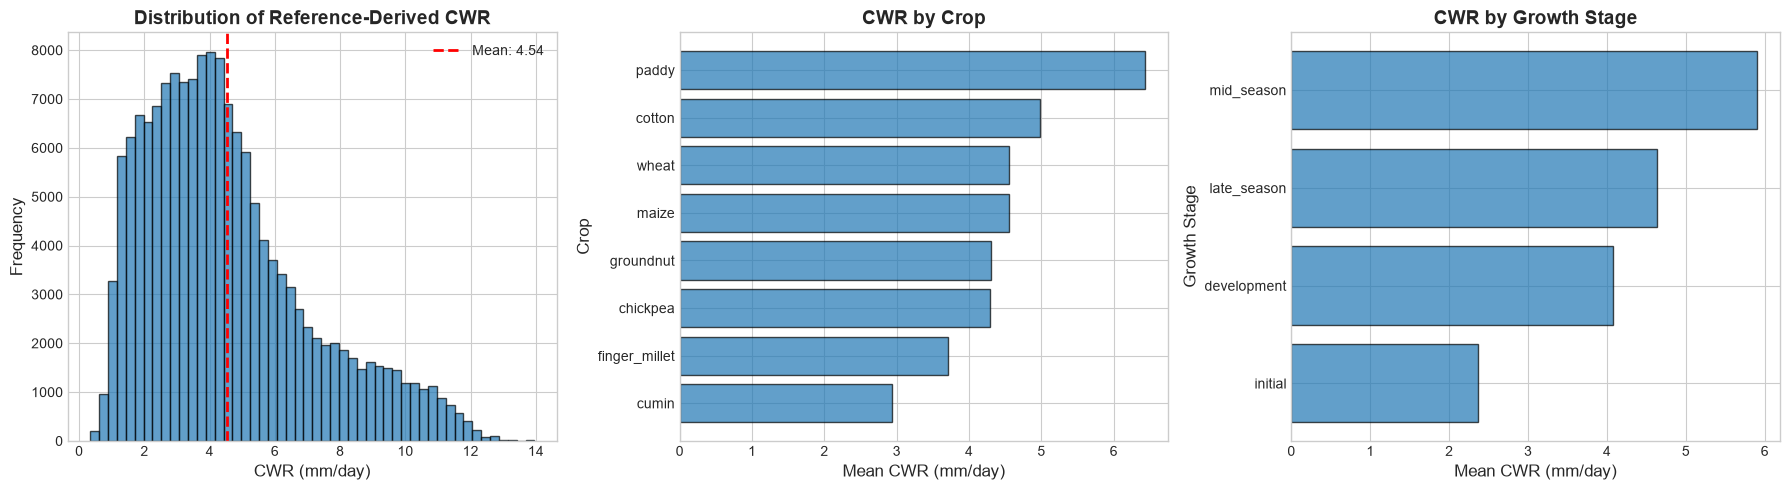


Interpretation:
- The distribution shows the range of reference-derived daily CWR values in the current modelling dataset.
- Different crops have different water requirements based on their Kc curves.
- Growth stages show how water demand varies through the crop cycle.
- Do not claim that this proves field water consumption; it is reference-derived.


In [10]:
import matplotlib.pyplot as plt

# Set up the plotting style
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribution of etc_mm_day
axes[0].hist(df['etc_mm_day'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('CWR (mm/day)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Distribution of Reference-Derived CWR', fontsize=14, fontweight='bold')
axes[0].axvline(df['etc_mm_day'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["etc_mm_day"].mean():.2f}')
axes[0].legend()

# Plot 2: CWR by crop
crop_cwr = df.groupby('crop')['etc_mm_day'].mean().sort_values()
axes[1].barh(crop_cwr.index, crop_cwr.values, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Mean CWR (mm/day)', fontsize=12)
axes[1].set_ylabel('Crop', fontsize=12)
axes[1].set_title('CWR by Crop', fontsize=14, fontweight='bold')

# Plot 3: CWR by growth stage
stage_cwr = df.groupby('growth_stage')['etc_mm_day'].mean().sort_values()
axes[2].barh(stage_cwr.index, stage_cwr.values, edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Mean CWR (mm/day)', fontsize=12)
axes[2].set_ylabel('Growth Stage', fontsize=12)
axes[2].set_title('CWR by Growth Stage', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- The distribution shows the range of reference-derived daily CWR values in the current modelling dataset.")
print("- Different crops have different water requirements based on their Kc curves.")
print("- Growth stages show how water demand varies through the crop cycle.")
print("- Do not claim that this proves field water consumption; it is reference-derived.")

## 10. Current Active XGBoost Model

In [11]:
import json

# Load model metadata
model_metadata_path = PROJECT_ROOT / "artifacts" / "models" / "reduced_input" / "v1" / "metadata.json"

with open(model_metadata_path, 'r') as f:
    model_metadata = json.load(f)

print("Active Model Information:\n")
print(f"Model Name: {model_metadata['model_name']}")
print(f"Model Version: {model_metadata['version']}")
print(f"Algorithm: {model_metadata['algorithm']}")
print(f"Task: {model_metadata['task']['task']}")
print(f"Target: {model_metadata['task']['target']}")
print(f"Number of Features: {model_metadata['task']['n_features']}")

print("\nFeature Order:")
for i, feature in enumerate(model_metadata['feature_order'], 1):
    print(f"  {i}. {feature}")

print("\nNumerical Features:")
print(model_metadata['task']['numerical_features'])

print("\nCategorical Features:")
print(model_metadata['task']['categorical_features'])

print("\nThis is the EXISTING saved production model. Do NOT retrain it in this notebook.")

Active Model Information:

Model Name: reduced_input
Model Version: v1
Algorithm: XGBRegressor
Task: reduced_input
Target: etc_mm_day
Number of Features: 16

Feature Order:
  1. t2m
  2. t2m_min
  3. t2m_max
  4. rh2m
  5. temp_range_c
  6. rainfall_mm
  7. rain_sum_7d_mm
  8. rain_sum_30d_mm
  9. days_since_rain
  10. day_of_year
  11. doy_sin
  12. doy_cos
  13. month
  14. days_after_sowing
  15. crop
  16. growth_stage

Numerical Features:
['t2m', 't2m_min', 't2m_max', 'rh2m', 'temp_range_c', 'rainfall_mm', 'rain_sum_7d_mm', 'rain_sum_30d_mm', 'days_since_rain', 'day_of_year', 'doy_sin', 'doy_cos', 'month', 'days_after_sowing']

Categorical Features:
['crop', 'growth_stage']

This is the EXISTING saved production model. Do NOT retrain it in this notebook.


## 11. XGBoost Prediction

In [12]:
import joblib
import warnings

# Load the saved pipeline
pipeline_path = PROJECT_ROOT / "artifacts" / "models" / "reduced_input" / "v1" / "pipeline.joblib"

try:
    # Suppress version warnings for loading
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', category=UserWarning)
        pipeline = joblib.load(pipeline_path)
    print("Pipeline loaded successfully.\n")
    
    # Test if pipeline can predict
    test_input = pd.DataFrame([{f: 0 for f in model_metadata['feature_order']}])
    _ = pipeline.predict(test_input)
    print("Pipeline is executable.\n")
        
except Exception as e:
    print(f"Error loading pipeline: {e}")
    print("\nModel execution unavailable in the current notebook environment.")
    print("Reason: The saved model requires scikit-learn 1.7.1 for compatibility.")
    print("Please ensure you are using the .jalachakra-demo-venv environment.")
    pipeline = None

Pipeline loaded successfully.

Pipeline is executable.



In [13]:
if pipeline is not None:
    # Prepare the feature input for the demonstration record
    feature_order = model_metadata['feature_order']
    
    # Create input dictionary
    input_data = {}
    for feature in feature_order:
        if feature in demo_record.index:
            input_data[feature] = demo_record[feature]
    
    # Convert to DataFrame
    input_df = pd.DataFrame([input_data])
    
    # Make prediction
    prediction = pipeline.predict(input_df)[0]
    
    print("CURRENT XGBOOST PREDICTION\n")
    print(f"Predicted CWR: {prediction:.4f} mm/day")
    
    # Get conformal interval from metadata
    half_width = model_metadata['interval']['half_width_mm_day']
    print(f"\nLower Bound (from conformal calibration): {prediction - half_width:.4f} mm/day")
    print(f"Upper Bound (from conformal calibration): {prediction + half_width:.4f} mm/day")
    
    print(f"\nInterval width: {2 * half_width:.4f} mm/day")
    print(f"Nominal coverage: {model_metadata['interval']['nominal_coverage']}")
else:
    print("Prediction skipped due to pipeline loading error.")

CURRENT XGBOOST PREDICTION

Predicted CWR: 1.9281 mm/day

Lower Bound (from conformal calibration): 1.0783 mm/day
Upper Bound (from conformal calibration): 2.7779 mm/day

Interval width: 1.6996 mm/day
Nominal coverage: 0.9


## 12. Baseline vs XGBoost Comparison

In [14]:
print("BASELINE VS XGBOOST COMPARISON\n")
print("Method | CWR (mm/day)")
print("-" * 40)
print(f"Reference-derived CWR (target) | {demo_record['etc_mm_day']:.4f}")

if pipeline is not None and prediction is not None:
    print(f"Current XGBoost Prediction | {prediction:.4f}")
    
    # Add interval
    half_width = model_metadata['interval']['half_width_mm_day']
    print(f"XGBoost Lower Bound | {prediction - half_width:.4f}")
    print(f"XGBoost Upper Bound | {prediction + half_width:.4f}")
else:
    print("Current XGBoost Prediction | Not available (pipeline loading failed)")

print("\nIMPORTANT:")
print("Do NOT interpret this table as proof that XGBoost is more accurate.")
print("The current FAO-derived CWR is the reference-derived target.")
print("\nThis comparison is a demonstration of model behaviour relative to the current reference-derived target.")
print("Independent field-observed CWR ground truth is not currently available.")

BASELINE VS XGBOOST COMPARISON

Method | CWR (mm/day)
----------------------------------------
Reference-derived CWR (target) | 1.9489
Current XGBoost Prediction | 1.9281
XGBoost Lower Bound | 1.0783
XGBoost Upper Bound | 2.7779

IMPORTANT:
Do NOT interpret this table as proof that XGBoost is more accurate.
The current FAO-derived CWR is the reference-derived target.

This comparison is a demonstration of model behaviour relative to the current reference-derived target.
Independent field-observed CWR ground truth is not currently available.


## 13. Current Model Performance

In [15]:
print("EXISTING HELD-OUT EVALUATION RESULTS\n")
print("From the saved model artifact (reduced_input/v1):\n")

metrics = model_metadata['metrics']

print("Test Set Metrics:")
print(f"  MAE: {metrics['test']['mae_mm_day']:.4f} mm/day")
print(f"  RMSE: {metrics['test']['rmse_mm_day']:.4f} mm/day")
print(f"  R²: {metrics['test']['r2']:.4f}")
print(f"  NSE: {metrics['test']['nse']:.4f}")
print(f"  MAPE: {metrics['test']['mape_pct']:.2f}%")
print(f"  Bias: {metrics['test']['bias_mm_day']:.4f} mm/day")
print(f"  N (test samples): {metrics['test']['n']:,}")

print("\nCalibration Set Metrics:")
print(f"  MAE: {metrics['calibration']['mae_mm_day']:.4f} mm/day")
print(f"  RMSE: {metrics['calibration']['rmse_mm_day']:.4f} mm/day")
print(f"  R²: {metrics['calibration']['r2']:.4f}")
print(f"  N (calibration samples): {metrics['calibration']['n']:,}")

print("\nIMPORTANT:")
print("These are existing held-out evaluation results from the saved model artifact.")
print("Do NOT quote the surrogate diagnostic model's near-perfect performance as the production model accuracy.")
print("The active production model is: reduced_input/v1")

EXISTING HELD-OUT EVALUATION RESULTS

From the saved model artifact (reduced_input/v1):

Test Set Metrics:
  MAE: 0.3687 mm/day
  RMSE: 0.5105 mm/day
  R²: 0.9527
  NSE: 0.9527
  MAPE: 9.49%
  Bias: -0.0062 mm/day
  N (test samples): 31,560

Calibration Set Metrics:
  MAE: 0.3874 mm/day
  RMSE: 0.5498 mm/day
  R²: 0.9567
  N (calibration samples): 31,669

IMPORTANT:
These are existing held-out evaluation results from the saved model artifact.
Do NOT quote the surrogate diagnostic model's near-perfect performance as the production model accuracy.
The active production model is: reduced_input/v1


## 14. Prediction Uncertainty

In [16]:
print("UNCERTAINTY ANALYSIS\n")

interval = model_metadata['interval']

print("Conformal Prediction Interval:")
print(f"  Method: {interval['method']}")
print(f"  Nominal Coverage: {interval['nominal_coverage']}")
print(f"  Half Width: {interval['half_width_mm_day']:.4f} mm/day")
print(f"  Mean Interval Width: {interval['mean_interval_width_mm_day']:.4f} mm/day")
print(f"  Median Interval Width: {interval['median_interval_width_mm_day']:.4f} mm/day")
print(f"  Empirical Coverage: {interval['empirical_coverage']:.4f}")
print(f"  Coverage Gap: {interval['coverage_gap']:.4f}")
print(f"  N (calibration samples): {interval['n_calibration']:,}")

print("\nInterpretation:")
print("The interval represents an uncertainty range produced by the existing conformal calibration procedure.")
print("The empirical coverage (0.90) is very close to the nominal coverage (0.90), indicating good calibration.")
print("Do NOT call this probability of correctness unless the project's method specifically supports that interpretation.")

UNCERTAINTY ANALYSIS

Conformal Prediction Interval:
  Method: split conformal, absolute residual
  Nominal Coverage: 0.9
  Half Width: 0.8498 mm/day
  Mean Interval Width: 1.6986 mm/day
  Median Interval Width: 1.6997 mm/day
  Empirical Coverage: 0.9014
  Coverage Gap: 0.0014
  N (calibration samples): 31,669

Interpretation:
The interval represents an uncertainty range produced by the existing conformal calibration procedure.
The empirical coverage (0.90) is very close to the nominal coverage (0.90), indicating good calibration.
Do NOT call this probability of correctness unless the project's method specifically supports that interpretation.


## 15. Irrigation Requirement

In [17]:
print("IRRIGATION REQUIREMENT CALCULATION\n")

# Extract irrigation-related values from the demonstration record
cwr = demo_record['etc_mm_day']
effective_rainfall = demo_record['effective_rainfall_mm']
net_irrigation = demo_record['net_irrigation_mm']
gross_irrigation = demo_record['gross_irrigation_mm']
application_efficiency = demo_record['application_efficiency']

print("CWR (Crop Water Requirement):")
print(f"  {cwr:.4f} mm/day")

print("\nEffective Rainfall:")
print(f"  {effective_rainfall:.4f} mm/day")

print("\nNet Irrigation Requirement:")
print(f"  {net_irrigation:.4f} mm/day")
print(f"  (CWR - Effective Rainfall, floored at zero)")

print("\nGross Irrigation Requirement:")
print(f"  {gross_irrigation:.4f} mm/day")
print(f"  (Net / Application Efficiency)")

print("\nApplication Efficiency:")
print(f"  {application_efficiency:.2f} (furrow irrigation)")

print("\nIMPORTANT DISTINCTIONS:")
print("- CWR ≠ Net Irrigation Requirement")
print("- Net Irrigation Requirement ≠ Gross Irrigation Requirement")
print("- CWR is what the crop needs (ETc)")
print("- Net irrigation is what must be supplied after rainfall contribution")
print("- Gross irrigation is what must be delivered accounting for system efficiency")

IRRIGATION REQUIREMENT CALCULATION

CWR (Crop Water Requirement):
  1.9489 mm/day

Effective Rainfall:
  0.0000 mm/day

Net Irrigation Requirement:
  1.9489 mm/day
  (CWR - Effective Rainfall, floored at zero)

Gross Irrigation Requirement:
  2.9983 mm/day
  (Net / Application Efficiency)

Application Efficiency:
  0.65 (furrow irrigation)

IMPORTANT DISTINCTIONS:
- CWR ≠ Net Irrigation Requirement
- Net Irrigation Requirement ≠ Gross Irrigation Requirement
- CWR is what the crop needs (ETc)
- Net irrigation is what must be supplied after rainfall contribution
- Gross irrigation is what must be delivered accounting for system efficiency


## 16. Water Volume Calculation

In [18]:
# Water volume calculation (requires field area)
# Since field area is not in the dataset, we'll show the formula

print("WATER VOLUME CALCULATION\n")

print("Field Area: Not available from the current record")
print("\nGross Irrigation Depth:")
print(f"  {gross_irrigation:.4f} mm")

print("\nFormula for Water Volume:")
print("  Volume (litres) = Depth (mm) × Area (hectares) × 10,000")

print("\nExample (if field area = 1 hectare):")
example_area = 1.0
example_volume = gross_irrigation * example_area * 10000
print(f"  Estimated Water Volume: {example_volume:.2f} litres")

print("\nClearly state that volume depends on field area.")

WATER VOLUME CALCULATION

Field Area: Not available from the current record

Gross Irrigation Depth:
  2.9983 mm

Formula for Water Volume:
  Volume (litres) = Depth (mm) × Area (hectares) × 10,000

Example (if field area = 1 hectare):
  Estimated Water Volume: 29982.60 litres

Clearly state that volume depends on field area.


## 17. Farmer Advisory

In [19]:
print("FARMER ADVISORY\n")

print("Crop:", demo_record['crop'])
print("Growth Stage:", demo_record['growth_stage'])
print(f"Days After Sowing: {demo_record['days_after_sowing']:.0f}")

print(f"\nWater Demand: {cwr:.2f} mm/day")
print(f"Effective Rainfall: {effective_rainfall:.2f} mm")
print(f"Irrigation Requirement: {net_irrigation:.2f} mm")

# Simple advisory logic based on irrigation trigger
if net_irrigation > 0:
    advisory = "IRRIGATE TODAY"
    reason = f"Crop water demand ({cwr:.2f} mm/day) exceeds effective rainfall ({effective_rainfall:.2f} mm)."
else:
    advisory = "NO IRRIGATION NEEDED"
    reason = f"Effective rainfall ({effective_rainfall:.2f} mm) meets or exceeds crop water demand ({cwr:.2f} mm/day)."

print(f"\nAdvisory: {advisory}")
print(f"Reason: {reason}")

print("\nNote: This is a simplified advisory for demonstration.")
print("The production system uses more sophisticated logic including root-zone depletion tracking.")

FARMER ADVISORY

Crop: chickpea
Growth Stage: initial
Days After Sowing: 0

Water Demand: 1.95 mm/day
Effective Rainfall: 0.00 mm
Irrigation Requirement: 1.95 mm

Advisory: IRRIGATE TODAY
Reason: Crop water demand (1.95 mm/day) exceeds effective rainfall (0.00 mm).

Note: This is a simplified advisory for demonstration.
The production system uses more sophisticated logic including root-zone depletion tracking.


## 18. Research Methodology Summary

### RESEARCH METHODOLOGY

**Step 1**
Use cleaned and validated agricultural/weather datasets.

**Step 2**
Prepare the weather information.

**Step 3**
Calculate reference evapotranspiration (ET₀) using FAO-56 Penman-Monteith.

**Step 4**
Determine the crop growth stage using the current project's calendar-day approach.

**Step 5**
Obtain the appropriate crop coefficient Kc.

**Step 6**
Calculate: ETc = ET₀ × Kc

**Step 7**
Treat ETc as the current reference-derived CWR target.

**Step 8**
Use the existing XGBoost model to generate the current ML prediction.

**Step 9**
Use irrigation logic to account separately for rainfall, soil/root-zone contribution and irrigation efficiency.

**Step 10**
Produce a farmer-facing irrigation advisory.

## 19. Research Experiment Map

### CURRENT MODEL STATUS

**Reference baseline:** FAO-56 Penman-Monteith ET₀ × growth-stage Kc produces the reference-derived `etc_mm_day` target.

**Reduced-input model:** `reduced_input/v1` is already trained and evaluated with a chronological train/calibration/test split. The saved XGBoost artifact estimates the reference target without solar radiation or wind; it does not predict field-measured water use.

**Forecasting:** the separate seven-day forecast task is not trained yet.

See `notebooks/04_baseline_model.ipynb` for an independent held-out evaluation of the existing reduced-input artifact. No model is retrained by that notebook.

## 20. Important Research Limitations

In [20]:
print("IMPORTANT RESEARCH LIMITATIONS\n")

limitations = model_metadata['baseline_assumptions']['limitations']

for i, limitation in enumerate(limitations, 1):
    print(f"{i}. {limitation}")

print("\nAdditional Limitations:")
print("- Target is reference-derived, not field-observed")
print("- Current growth stage is calendar-day-based (not GDD-based)")
print("- Geographic provenance of the climate dataset is unresolved")
print("- Site coordinates are inferred from radiation data (23.7°N, 300m elevation)")
print("- Soil information is estimated, not measured")
print("- No soil moisture sensor exists in this project")
print("- Application efficiencies are indicative published values, not field measurements")
print("- Sowing dates are a designed sweep, not observed planting dates")
print("- Independent observed CWR ground truth is not currently available")

print("\nThese limitations are documented and must be acknowledged in any reporting.")

IMPORTANT RESEARCH LIMITATIONS

1. The target is reference-derived, not an observed field measurement.
2. Site geography is unresolved; ET0 varies by about 1.7 percent across the plausible envelope.
3. Application efficiencies are indicative published values, not measurements at any field in this study.
4. Root-zone depletion is a bookkeeping estimate with no sensor behind it.
5. Sowing dates are a designed sweep, not observed planting.

Additional Limitations:
- Target is reference-derived, not field-observed
- Current growth stage is calendar-day-based (not GDD-based)
- Geographic provenance of the climate dataset is unresolved
- Site coordinates are inferred from radiation data (23.7°N, 300m elevation)
- Soil information is estimated, not measured
- No soil moisture sensor exists in this project
- Application efficiencies are indicative published values, not field measurements
- Sowing dates are a designed sweep, not observed planting dates
- Independent observed CWR ground truth is

## 21. Viva / Guide Questions

### Questions I Should Be Able to Answer

1. What problem does Jalachakra solve?
2. What is ET₀?
3. Why do we calculate ET₀?
4. What is Kc?
5. Why does Kc depend on growth stage?
6. What is ETc?
7. How is CWR calculated?
8. Why is CWR not the same as irrigation requirement?
9. What is effective rainfall?
10. How does soil information affect irrigation?
11. Why did we use XGBoost?
12. What features does the current XGBoost model use?
13. What is the current model target?
14. Is the target field-observed?
15. How did we avoid target leakage?
16. Why use chronological train/test splitting?
17. What is prediction uncertainty?
18. What is Experiment 1?
19. What are Experiment 2 and 3?
20. What are the current research limitations?

## 22. Summary

In [21]:
print("NOTEBOOK SUMMARY\n")
print("This notebook demonstrates:")
print("1. Loading the processed CWR baseline panel dataset")
print("2. Inspecting a real demonstration record")
print("3. Determining growth stage using calendar-day approach")
print("4. Obtaining Kc from the crop coefficient model")
print("5. Understanding FAO-56 ET₀ calculation")
print("6. Computing ETc = ET₀ × Kc as reference-derived CWR")
print("7. Analyzing CWR distribution across crops and growth stages")
print("8. Loading the existing XGBoost model (reduced_input/v1)")
print("9. Demonstrating model prediction and uncertainty")
print("10. Calculating irrigation requirement from CWR and rainfall")
print("11. Producing a simple farmer advisory")
print("12. Documenting research methodology and limitations")

print("\nAll calculations use existing project modules and real data.")
print("No results are fabricated.")

NOTEBOOK SUMMARY

This notebook demonstrates:
1. Loading the processed CWR baseline panel dataset
2. Inspecting a real demonstration record
3. Determining growth stage using calendar-day approach
4. Obtaining Kc from the crop coefficient model
5. Understanding FAO-56 ET₀ calculation
6. Computing ETc = ET₀ × Kc as reference-derived CWR
7. Analyzing CWR distribution across crops and growth stages
8. Loading the existing XGBoost model (reduced_input/v1)
9. Demonstrating model prediction and uncertainty
10. Calculating irrigation requirement from CWR and rainfall
11. Producing a simple farmer advisory
12. Documenting research methodology and limitations

All calculations use existing project modules and real data.
No results are fabricated.
